# Tuning Interattivo Parametri Edge Detection (Reference Set)

Questo notebook fornisce l'interfaccia grafica interattiva (ipywidgets) per effettuare il tuning fine dei parametri di estrazione contorni (CLAHE, Bilateral Filter, soglie Canny T1/T2) per ciascuna delle 8 monete di riferimento.

I parametri calibrati vengono salvati direttamente nel file di configurazione condiviso:
pipeline/conf/Flow_A_Reference/edge_params.json

La pipeline principale (pipeline/src/Flow_A_Reference/flow_A_reference.ipynb) leggerà automaticamente tali parametri per generare ed estrarre gli edge finali senza mostrare widget interattivi a schermo.


In [1]:
import sys
from pathlib import Path
import cv2
from IPython.display import display

# Risoluzione del percorso root del progetto in modo relativo
current_dir = Path.cwd().resolve()
project_root = current_dir
for parent in [current_dir] + list(current_dir.parents):
    if (parent / 'pipeline' / 'src' / 'Flow_A_Reference').exists():
        project_root = parent
        break

flow_a_src = project_root / 'pipeline' / 'src' / 'Flow_A_Reference'
if str(flow_a_src) not in sys.path:
    sys.path.insert(0, str(flow_a_src))

from module1_load_references import load_reference_images
from module2_extract_roi import extract_and_save_rois
from module4_extract_edges import (
    convert_and_save_gray_rois,
    load_or_create_edge_params,
    save_edge_params,
    create_edge_tuner_widget,
    apply_edge_pipeline,
    plot_all_edges
)

print(f'Project root: {project_root}')
print(f'Moduli importati da: {flow_a_src.relative_to(project_root)}')


Project root: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV
Moduli importati da: pipeline\src\Flow_A_Reference


In [2]:
# ==========================================
# 1. Caricamento ROI Grayscale delle 8 Reference
# ==========================================
gray_artifacts_dir = project_root / 'pipeline' / 'artifacts' / 'Flow_A_Reference' / 'module4_rois_gray'
ref_rois_gray = {}

if gray_artifacts_dir.exists() and len(list(gray_artifacts_dir.glob('*_gray.png'))) == 8:
    print(f'Caricamento delle 8 ROI Grayscale da artifacts: {gray_artifacts_dir.relative_to(project_root)}')
    for p in sorted(gray_artifacts_dir.glob('*_gray.png')):
        coin_name = p.stem.replace('_gray', '')
        ref_rois_gray[coin_name] = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
else:
    print('ROI Grayscale non presenti negli artifacts. Esecuzione caricamento reference ed estrazione ROI...')
    ref_images = load_reference_images()
    ref_rois = extract_and_save_rois(ref_images)
    ref_rois_gray = convert_and_save_gray_rois(ref_rois)

print(f'Pronte {len(ref_rois_gray)} monete per il tuning: {list(ref_rois_gray.keys())}')


Caricamento delle 8 ROI Grayscale da artifacts: pipeline\artifacts\Flow_A_Reference\module4_rois_gray
Pronte 8 monete per il tuning: ['10cent', '1cent', '1euro', '20cent', '2cent', '2euro', '50cent', '5cent']


In [3]:
# ==========================================
# 2. Caricamento Configurazione Corrente da conf/
# ==========================================
conf_path = project_root / 'pipeline' / 'conf' / 'Flow_A_Reference' / 'edge_params.json'
edge_params = load_or_create_edge_params(conf_path)
print(f'Parametri caricati da: {conf_path.relative_to(project_root)}')


Parametri caricati da: pipeline\conf\Flow_A_Reference\edge_params.json


In [4]:
# ==========================================
# 3. Interfaccia Interattiva di Tuning (ipywidgets)
# ==========================================
# Regola i parametri per ciascuna moneta:
# Cliccando su 'Salva Parametri', le impostazioni vengono scritte su pipeline/conf/Flow_A_Reference/edge_params.json
def on_save_callback(updated_params):
    save_edge_params(updated_params, conf_path)
    print(f'Parametri salvati in: {conf_path.relative_to(project_root)}')

tuner_widget = create_edge_tuner_widget(
    ref_rois_gray,
    edge_params,
    on_save_callback=on_save_callback,
    json_path=conf_path
)

if tuner_widget is not None:
    display(tuner_widget)
else:
    print('Widget non disponibile: assicurarsi che ipywidgets sia installato.')


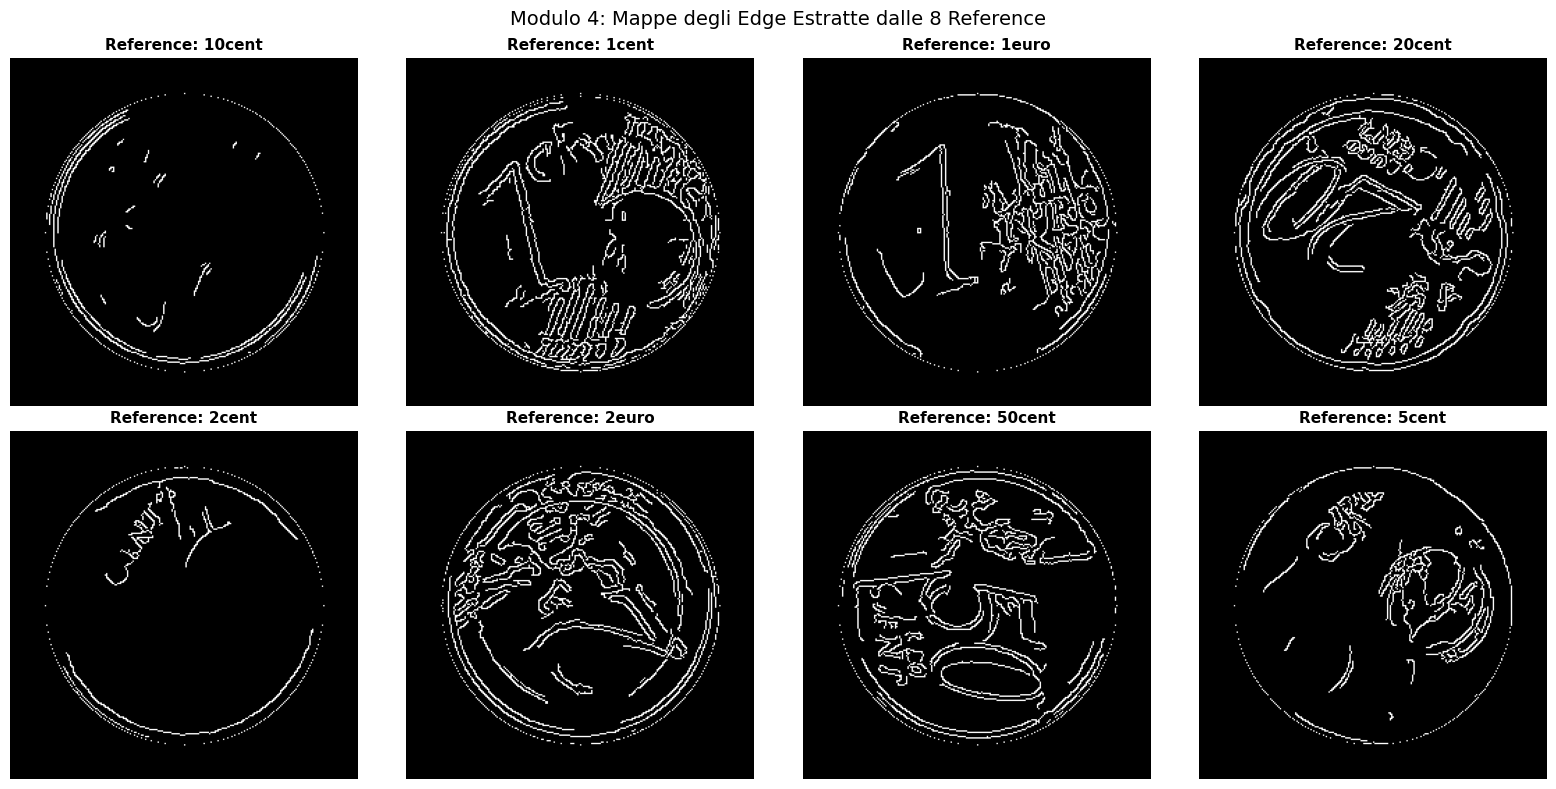

In [6]:
# ==========================================
# 4. (Opzionale) Anteprima Complessiva degli 8 Edge
# ==========================================
# Mostra la griglia 2x4 riassuntiva con i parametri attualmente salvati
current_edges = {name: apply_edge_pipeline(gray, edge_params[name]) for name, gray in ref_rois_gray.items()}
plot_all_edges(current_edges, save_plot=False)
